In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Customer Segmentation Project Started!")

Customer Segmentation Project Started!


In [4]:
df = pd.read_csv("../dataset/customer_segmentation_data.csv")

df.head()

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount
0,1,38,Female,99342,90,3,24,Groceries,113.53
1,2,21,Female,78852,60,2,42,Sports,41.93
2,3,60,Female,126573,30,2,28,Clothing,424.36
3,4,40,Other,47099,74,9,5,Home & Garden,991.93
4,5,65,Female,140621,21,3,25,Electronics,347.08


In [5]:
df.shape

(1000, 9)

In [6]:
df.columns

Index(['id', 'age', 'gender', 'income', 'spending_score', 'membership_years',
       'purchase_frequency', 'preferred_category', 'last_purchase_amount'],
      dtype='str')

In [7]:
df.dtypes

id                        int64
age                       int64
gender                      str
income                    int64
spending_score            int64
membership_years          int64
purchase_frequency        int64
preferred_category          str
last_purchase_amount    float64
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1000 non-null   int64  
 1   age                   1000 non-null   int64  
 2   gender                1000 non-null   str    
 3   income                1000 non-null   int64  
 4   spending_score        1000 non-null   int64  
 5   membership_years      1000 non-null   int64  
 6   purchase_frequency    1000 non-null   int64  
 7   preferred_category    1000 non-null   str    
 8   last_purchase_amount  1000 non-null   float64
dtypes: float64(1), int64(6), str(2)
memory usage: 70.4 KB


In [9]:
df.describe()

,id,age,income,spending_score,membership_years,purchase_frequency,last_purchase_amount
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,500.500000,43.783000,88500.800000,50.685000,5.46900,26.596000,492.348670
std,288.819436,15.042213,34230.771122,28.955175,2.85573,14.243654,295.744253
min,1.000000,18.000000,30004.000000,1.000000,1.00000,1.000000,10.400000
25%,250.750000,30.000000,57911.750000,26.000000,3.00000,15.000000,218.762500
50%,500.500000,45.000000,87845.500000,50.000000,5.00000,27.000000,491.595000
75%,750.250000,57.000000,116110.250000,76.000000,8.00000,39.000000,747.170000
max,1000.000000,69.000000,149973.000000,100.000000,10.00000,50.000000,999.740000


In [10]:
# Check missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
id                      0
age                     0
gender                  0
income                  0
spending_score          0
membership_years        0
purchase_frequency      0
preferred_category      0
last_purchase_amount    0
dtype: int64


In [11]:
# Check duplicate records
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [12]:
# Check unique values
for column in df.columns:
    print(column, ":", df[column].nunique())

id : 1000
age : 52
gender : 3
income : 996
spending_score : 100
membership_years : 10
purchase_frequency : 50
preferred_category : 5
last_purchase_amount : 994


In [13]:
# Gender distribution
print(df['gender'].value_counts())
# Preferred category distribution
print(df['preferred_category'].value_counts())

gender
Male      357
Other     327
Female    316
Name: count, dtype: int64
preferred_category
Electronics      215
Sports           210
Home & Garden    206
Groceries        199
Clothing         170
Name: count, dtype: int64


In [14]:
# Select numerical columns
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns
print(numerical_columns)

Index(['id', 'age', 'income', 'spending_score', 'membership_years',
       'purchase_frequency', 'last_purchase_amount'],
      dtype='str')


In [15]:
# Statistical analysis
print(df[numerical_columns].describe().T)

                       count         mean           std      min         25%  \
id                    1000.0    500.50000    288.819436      1.0    250.7500   
age                   1000.0     43.78300     15.042213     18.0     30.0000   
income                1000.0  88500.80000  34230.771122  30004.0  57911.7500   
spending_score        1000.0     50.68500     28.955175      1.0     26.0000   
membership_years      1000.0      5.46900      2.855730      1.0      3.0000   
purchase_frequency    1000.0     26.59600     14.243654      1.0     15.0000   
last_purchase_amount  1000.0    492.34867    295.744253     10.4    218.7625   

                            50%        75%        max  
id                      500.500     750.25    1000.00  
age                      45.000      57.00      69.00  
income                87845.500  116110.25  149973.00  
spending_score           50.000      76.00     100.00  
membership_years          5.000       8.00      10.00  
purchase_frequency     

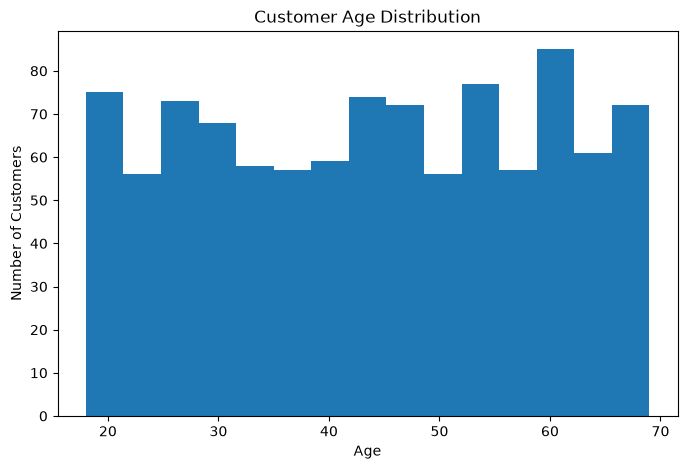

In [16]:
plt.figure(figsize=(8,5))

plt.hist(df['age'], bins=15)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

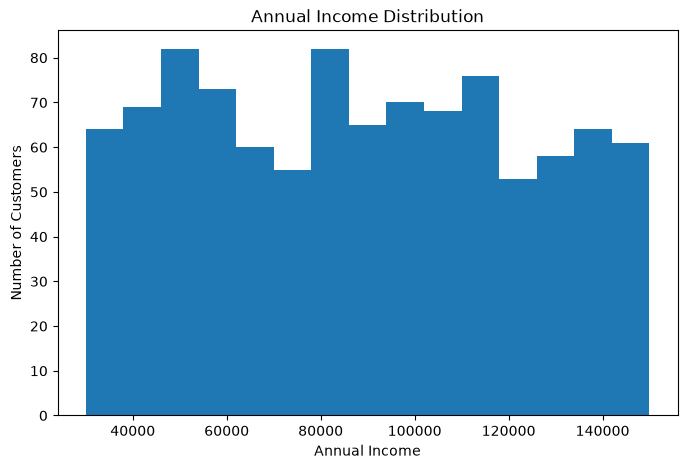

In [17]:
plt.figure(figsize=(8,5))

plt.hist(df['income'], bins=15)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Number of Customers")

plt.show()

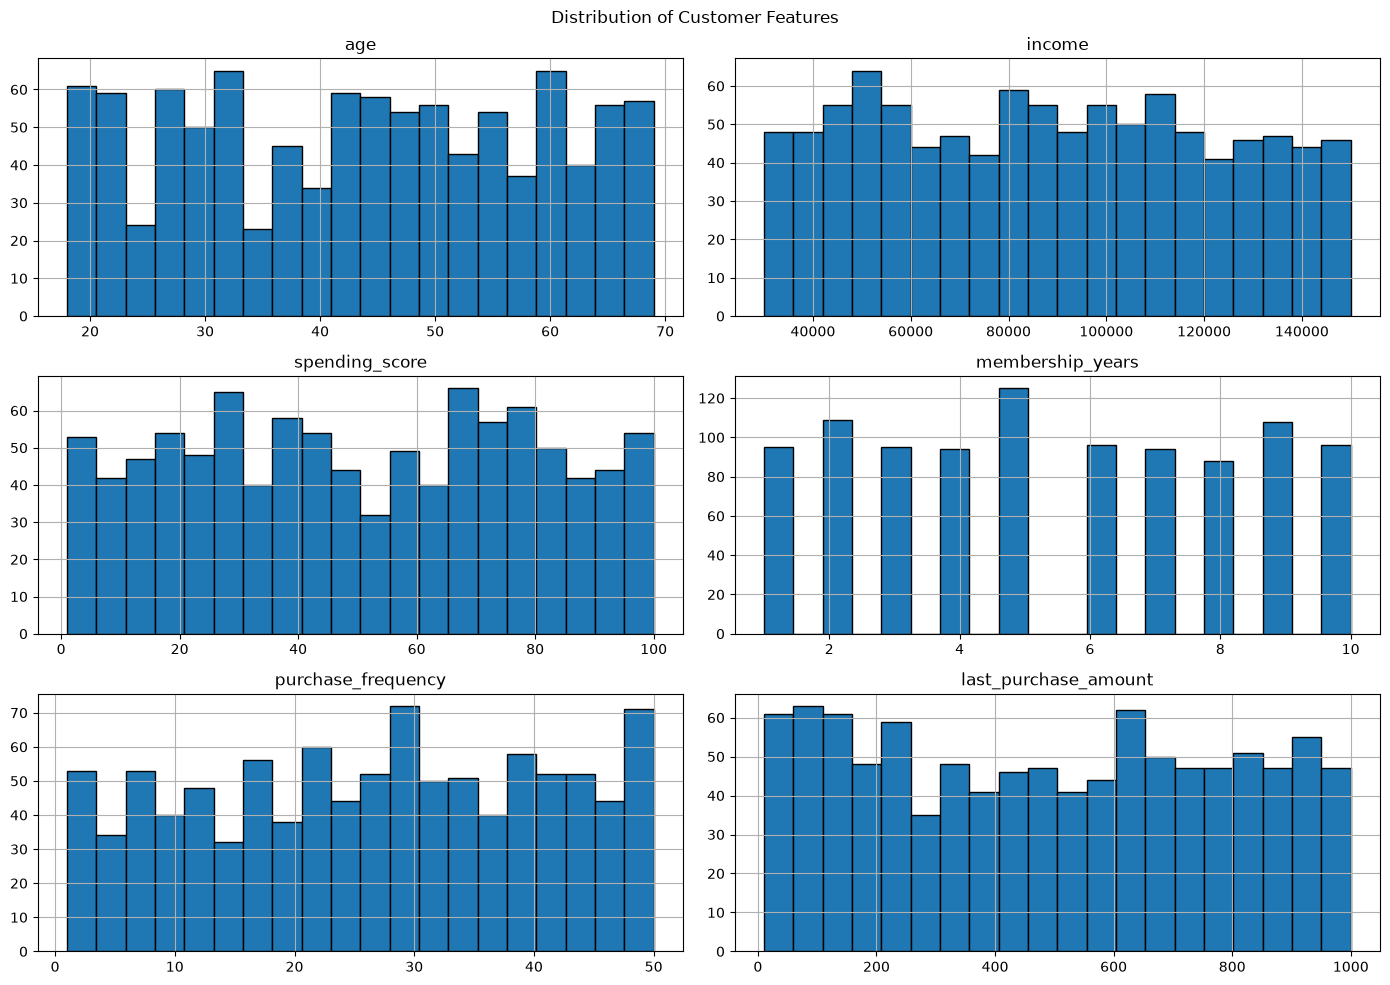

In [18]:
# Select useful numerical features
# Exclude customer ID

features = [
    'age',
    'income',
    'spending_score',
    'membership_years',
    'purchase_frequency',
    'last_purchase_amount'
]

# Plot distributions

df[features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Distribution of Customer Features")

plt.tight_layout()

plt.show()

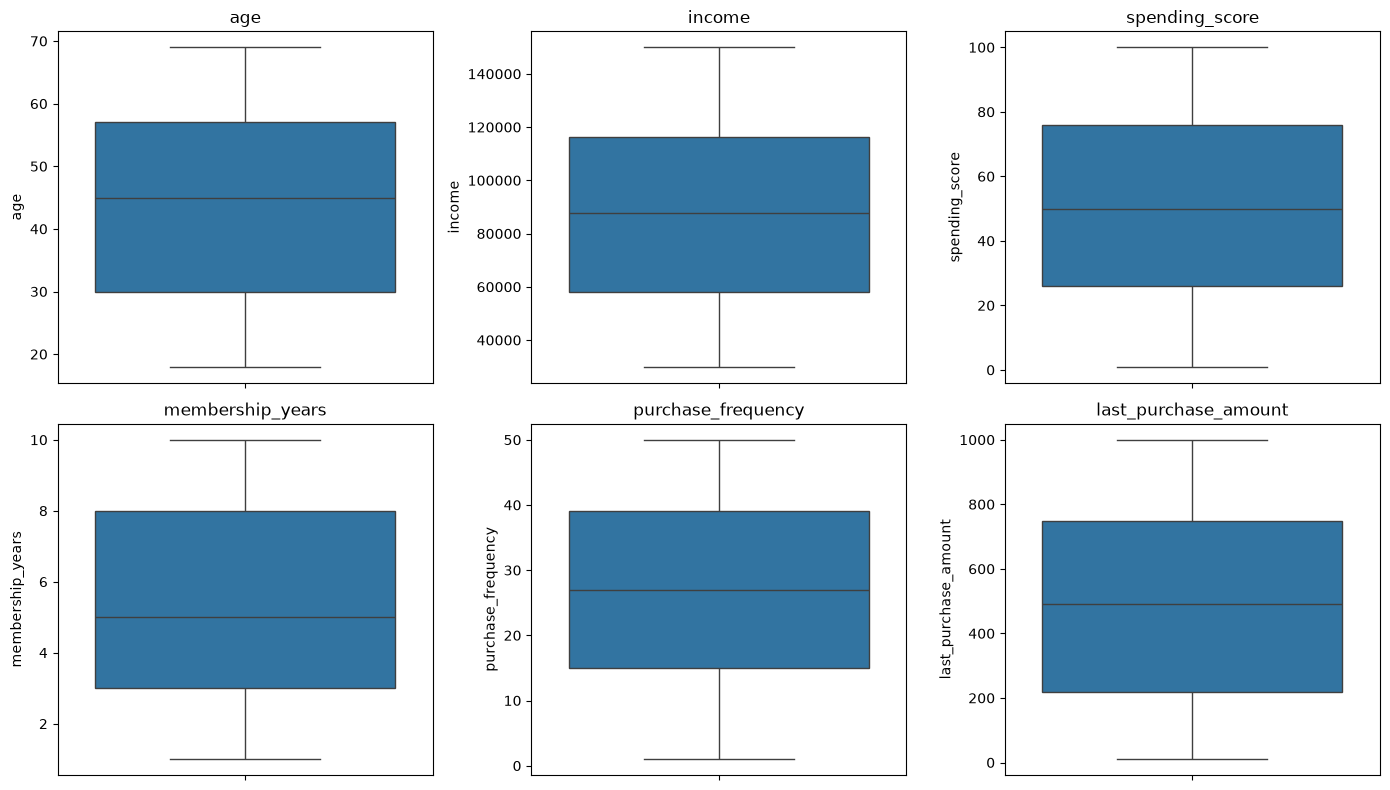

In [19]:
plt.figure(figsize=(14, 8))

for i, column in enumerate(features, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(y=df[column])

    plt.title(column)

plt.tight_layout()

plt.show()

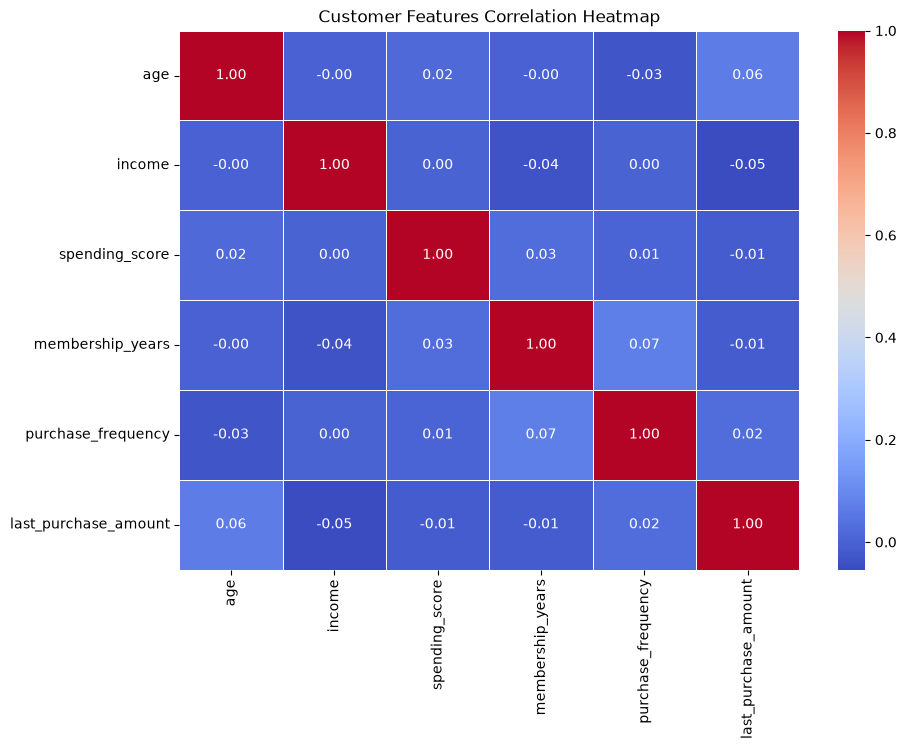

In [20]:
# Calculate correlation

correlation = df[features].corr()

# Create heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Customer Features Correlation Heatmap")

plt.show()

In [21]:
# Outlier detection using IQR method

for column in features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(f"\nFeature: {column}")
    print("Lower Limit:", round(lower_limit, 2))
    print("Upper Limit:", round(upper_limit, 2))
    print("Outlier Count:", len(outliers))


Feature: age
Lower Limit: -10.5
Upper Limit: 97.5
Outlier Count: 0

Feature: income
Lower Limit: -29386.0
Upper Limit: 203408.0
Outlier Count: 0

Feature: spending_score
Lower Limit: -49.0
Upper Limit: 151.0
Outlier Count: 0

Feature: membership_years
Lower Limit: -4.5
Upper Limit: 15.5
Outlier Count: 0

Feature: purchase_frequency
Lower Limit: -21.0
Upper Limit: 75.0
Outlier Count: 0

Feature: last_purchase_amount
Lower Limit: -573.85
Upper Limit: 1539.78
Outlier Count: 0


In [22]:
%pip install -U scikit-learn
from sklearn.preprocessing import StandardScaler

# Select model features

X = df[features].copy()

# Create StandardScaler object

scaler = StandardScaler()

# Apply feature scaling

X_scaled = scaler.fit_transform(X)

# Convert scaled data into DataFrame

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=df.index
)

print(X_scaled.head())

Note: you may need to restart the kernel to use updated packages.
        age    income  spending_score  membership_years  purchase_frequency  \
0 -0.384644  0.316868        1.358468         -0.865010           -0.182348   
1 -1.515362 -0.282016        0.321865         -1.215358            1.082005   
2  1.078639  1.112778       -0.714738         -1.215358            0.098620   
3 -0.251618 -1.210096        0.805613          1.237080           -1.516943   
4  1.411203  1.523374       -1.025718         -0.865010           -0.112106   

   last_purchase_amount  
0             -1.281540  
1             -1.523763  
2             -0.230005  
3              1.690080  
4             -0.491443  


In [23]:
print("Scaled Data Statistics:")
print(X_scaled.describe().round(2))

Scaled Data Statistics:
           age   income  spending_score  membership_years  purchase_frequency  \
count  1000.00  1000.00         1000.00           1000.00             1000.00   
mean     -0.00    -0.00           -0.00             -0.00               -0.00   
std       1.00     1.00            1.00              1.00                1.00   
min      -1.71    -1.71           -1.72             -1.57               -1.80   
25%      -0.92    -0.89           -0.85             -0.87               -0.81   
50%       0.08    -0.02           -0.02             -0.16                0.03   
75%       0.88     0.81            0.87              0.89                0.87   
max       1.68     1.80            1.70              1.59                1.64   

       last_purchase_amount  
count               1000.00  
mean                  -0.00  
std                    1.00  
min                   -1.63  
25%                   -0.93  
50%                   -0.00  
75%                    0.86  
max   

In [24]:
# Select final model features

model_features = [
    'income',
    'spending_score',
    'membership_years',
    'purchase_frequency',
    'last_purchase_amount'
]

# Create feature dataset
X = df[model_features].copy()

# Apply StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Convert into DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=model_features,
    index=df.index
)

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)

print("\nScaled feature statistics:")
print(X_scaled.describe().round(2))

Original shape: (1000, 5)
Scaled shape: (1000, 5)

Scaled feature statistics:
        income  spending_score  membership_years  purchase_frequency  \
count  1000.00         1000.00           1000.00             1000.00   
mean     -0.00           -0.00             -0.00               -0.00   
std       1.00            1.00              1.00                1.00   
min      -1.71           -1.72             -1.57               -1.80   
25%      -0.89           -0.85             -0.87               -0.81   
50%      -0.02           -0.02             -0.16                0.03   
75%       0.81            0.87              0.89                0.87   
max       1.80            1.70              1.59                1.64   

       last_purchase_amount  
count               1000.00  
mean                  -0.00  
std                    1.00  
min                   -1.63  
25%                   -0.93  
50%                   -0.00  
75%                    0.86  
max                    1.72  


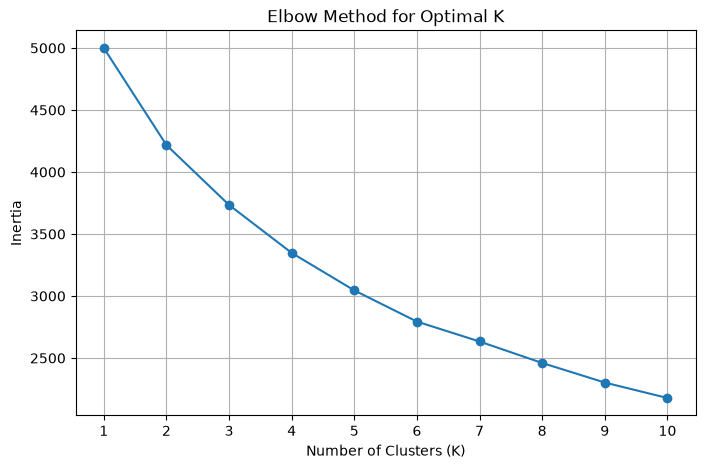

In [25]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Store inertia values
inertia_values = []

# Test different cluster numbers
K_values = range(1, 11)

for k in K_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

# Plot Elbow graph
plt.figure(figsize=(8, 5))

plt.plot(
    K_values,
    inertia_values,
    marker='o'
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(K_values)
plt.grid(True)

plt.show()

In [26]:
# STEP 1: Import required library

import pandas as pd
from sklearn.preprocessing import StandardScaler

# STEP 2: Select five model features

model_features = [
    'income',
    'spending_score',
    'membership_years',
    'purchase_frequency',
    'last_purchase_amount'
]

# STEP 3: Create feature dataset

X = df[model_features].copy()

# STEP 4: Apply StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# STEP 5: Convert into DataFrame

X_scaled = pd.DataFrame(
    X_scaled,
    columns=model_features,
    index=df.index
)

# STEP 6: Verify

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)

print("\nScaled Statistics:")
print(X_scaled.describe().round(2))

Original shape: (1000, 5)
Scaled shape: (1000, 5)

Scaled Statistics:
        income  spending_score  membership_years  purchase_frequency  \
count  1000.00         1000.00           1000.00             1000.00   
mean     -0.00           -0.00             -0.00               -0.00   
std       1.00            1.00              1.00                1.00   
min      -1.71           -1.72             -1.57               -1.80   
25%      -0.89           -0.85             -0.87               -0.81   
50%      -0.02           -0.02             -0.16                0.03   
75%       0.81            0.87              0.89                0.87   
max       1.80            1.70              1.59                1.64   

       last_purchase_amount  
count               1000.00  
mean                  -0.00  
std                    1.00  
min                   -1.63  
25%                   -0.93  
50%                   -0.00  
75%                    0.86  
max                    1.72  


In [28]:

# STEP 1: Import required libraries

from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

import pandas as pd


# STEP 2: Store evaluation results

results = []


# STEP 3: Test different cluster numbers

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Train model and assign labels
    labels = kmeans.fit_predict(X_scaled)

    # Calculate evaluation metrics
    silhouette = silhouette_score(
        X_scaled, labels
    )

    db_index = davies_bouldin_score(
        X_scaled, labels
    )

    ch_score = calinski_harabasz_score(
        X_scaled, labels
    )

    # Store results
    results.append({
        'K': k,
        'Inertia': kmeans.inertia_,
        'Silhouette Score': silhouette,
        'Davies-Bouldin Index': db_index,
        'Calinski-Harabasz Score': ch_score
    })


# STEP 4: Convert results into DataFrame

evaluation_df = pd.DataFrame(results)


# STEP 5: Display results

print("K-Means Clustering Evaluation:")
print(evaluation_df.round(4).to_string(index=False))


K-Means Clustering Evaluation:
 K   Inertia  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Score
 2 4217.4473            0.1533                2.2620                 185.1802
 3 3734.4062            0.1446                1.9462                 168.9440
 4 3347.7608            0.1546                1.7675                 163.8538
 5 3045.3783            0.1583                1.6123                 159.6577
 6 2793.8620            0.1639                1.4920                 156.9799
 7 2633.3012            0.1645                1.4587                 148.7443
 8 2460.1363            0.1669                1.4193                 146.3069
 9 2302.2422            0.1775                1.3346                 145.1562
10 2177.7293            0.1757                1.3410                 142.5566


In [29]:

# STEP 1: Import KMeans

from sklearn.cluster import KMeans
import pandas as pd


# STEP 2: Train K=5 model

kmeans_5 = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

labels_5 = kmeans_5.fit_predict(X_scaled)


# STEP 3: Train K=9 model

kmeans_9 = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)

labels_9 = kmeans_9.fit_predict(X_scaled)


# STEP 4: Check cluster sizes

print("CUSTOMER DISTRIBUTION - K=5")

print(pd.Series(labels_5).value_counts().sort_index())


print("\nCUSTOMER DISTRIBUTION - K=9")

print(pd.Series(labels_9).value_counts().sort_index())


CUSTOMER DISTRIBUTION - K=5
0    224
1    201
2    182
3    198
4    195
Name: count, dtype: int64

CUSTOMER DISTRIBUTION - K=9
0    141
1    106
2    115
3    138
4    103
5     90
6    109
7     90
8    108
Name: count, dtype: int64


In [30]:

# Create customer datasets

customer_data_5 = df.copy()
customer_data_9 = df.copy()


# Add cluster labels

customer_data_5['cluster'] = labels_5
customer_data_9['cluster'] = labels_9


# Calculate average customer profiles

profile_5 = customer_data_5.groupby('cluster')[
    model_features
].mean().round(2)


profile_9 = customer_data_9.groupby('cluster')[
    model_features
].mean().round(2)


# Display results

print("CUSTOMER PROFILES - K=5")

print(profile_5)


print("\nCUSTOMER PROFILES - K=9")

print(profile_9)


CUSTOMER PROFILES - K=5
            income  spending_score  membership_years  purchase_frequency  \
cluster                                                                    
0         65097.55           39.13              7.20               28.83   
1         58792.19           46.11              3.97               25.97   
2        120335.32           23.48              3.95               24.51   
3        100950.28           78.72              3.58               20.99   
4        103654.02           65.58              8.37               32.32   

         last_purchase_amount  
cluster                        
0                      249.23  
1                      775.42  
2                      440.13  
3                      332.95  
4                      690.43  

CUSTOMER PROFILES - K=9
            income  spending_score  membership_years  purchase_frequency  \
cluster                                                                    
0         67615.61           25.40        

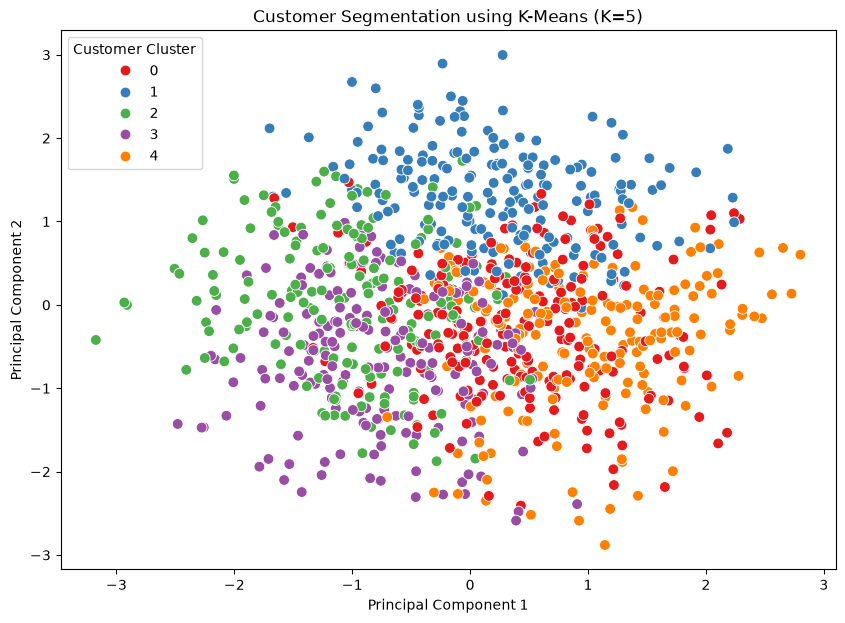

Explained variance ratio: [0.21786121 0.20977768]
Total explained variance: 42.76 %


In [31]:
# STEP 1: Import libraries

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA


# STEP 2: Apply PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)


# STEP 3: Create visualization dataset

pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2'],
    index=df.index
)

pca_df['cluster'] = labels_5


# STEP 4: Plot K=5 clusters

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='Set1',
    s=60
)

plt.title('Customer Segmentation using K-Means (K=5)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend(title='Customer Cluster')

plt.show()


# STEP 5: Explained variance

print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

In [32]:
# Create final customer dataset

customer_data = df.copy()

customer_data['cluster'] = labels_5


# STEP 1: Average age by cluster

print("AVERAGE AGE BY CLUSTER")

print(
    customer_data.groupby('cluster')['age']
    .mean()
    .round(2)
)


# STEP 2: Gender distribution

print("\nGENDER DISTRIBUTION")

print(
    pd.crosstab(
        customer_data['cluster'],
        customer_data['gender'],
        normalize='index'
    ).round(2) * 100
)


# STEP 3: Preferred category distribution

print("\nPREFERRED CATEGORY DISTRIBUTION")

print(
    pd.crosstab(
        customer_data['cluster'],
        customer_data['preferred_category'],
        normalize='index'
    ).round(2) * 100
)

AVERAGE AGE BY CLUSTER
cluster
0    43.27
1    45.35
2    42.77
3    42.88
4    44.61
Name: age, dtype: float64

GENDER DISTRIBUTION
gender   Female  Male  Other
cluster                     
0          35.0  36.0   29.0
1          27.0  35.0   38.0
2          29.0  39.0   32.0
3          38.0  31.0   31.0
4          28.0  37.0   34.0

PREFERRED CATEGORY DISTRIBUTION
preferred_category  Clothing  Electronics  Groceries  Home & Garden  Sports
cluster                                                                    
0                       19.0         25.0       19.0           18.0    19.0
1                       17.0         22.0       17.0           22.0    21.0
2                       14.0         21.0       20.0           25.0    20.0
3                       21.0         16.0       21.0           19.0    23.0
4                       14.0         23.0       22.0           20.0    22.0


In [33]:
# STEP 1: Create final dataset

final_customer_data = df.copy()

# STEP 2: Assign cluster labels

final_customer_data['cluster'] = labels_5


# STEP 3: Define business segment names

segment_names = {
    0: 'Loyal Budget Regulars',
    1: 'High Recent-Value Shoppers',
    2: 'Affluent Low-Spending Customers',
    3: 'High-Score Moderate-Frequency Shoppers',
    4: 'Loyal Premium Active Customers'
}


# STEP 4: Add segment names

final_customer_data['segment_name'] = (
    final_customer_data['cluster'].map(segment_names)
)


# STEP 5: Create final summary

segment_summary = (
    final_customer_data.groupby(
        ['cluster', 'segment_name']
    )
    .agg(
        customer_count=('cluster', 'size'),
        average_age=('age', 'mean'),
        average_income=('income', 'mean'),
        average_spending_score=('spending_score', 'mean'),
        average_membership=('membership_years', 'mean'),
        average_purchase_frequency=('purchase_frequency', 'mean'),
        average_purchase_amount=('last_purchase_amount', 'mean')
    )
    .round(2)
)


# STEP 6: Display results

print("FINAL CUSTOMER SEGMENTATION SUMMARY")

print(segment_summary)


# STEP 7: Export datasets

final_customer_data.to_csv(
    'mall_customer_segmentation_final.csv',
    index=False
)

segment_summary.to_csv(
    'mall_customer_segment_summary.csv'
)


print("\nFinal customer dataset exported successfully!")
print("Total customers:", len(final_customer_data))
print("Total segments:", final_customer_data['cluster'].nunique())

FINAL CUSTOMER SEGMENTATION SUMMARY
                                                customer_count  average_age  \
cluster segment_name                                                          
0       Loyal Budget Regulars                              224        43.27   
1       High Recent-Value Shoppers                         201        45.35   
2       Affluent Low-Spending Customers                    182        42.77   
3       High-Score Moderate-Frequency Shoppers             198        42.88   
4       Loyal Premium Active Customers                     195        44.61   

                                                average_income  \
cluster segment_name                                             
0       Loyal Budget Regulars                         65097.55   
1       High Recent-Value Shoppers                    58792.19   
2       Affluent Low-Spending Customers              120335.32   
3       High-Score Moderate-Frequency Shoppers       100950.28   
4       Loyal 

In [35]:
# STEP 1: Define customer segment names

segment_names = {
    0: 'Loyal Budget Regulars',
    1: 'Lower-Income High-Ticket Shoppers',
    2: 'Affluent Low-Spending Customers',
    3: 'High-Spending-Score Customers',
    4: 'Loyal Premium Active Customers'
}

# STEP 2: Assign segment names

final_customer_data['segment_name'] = (
    final_customer_data['cluster'].map(segment_names)
)

# STEP 3: Export final dataset

final_customer_data.to_csv(
    'mall_customer_segmentation_final.csv',
    index=False
)

# STEP 4: Verify export preparation

print("Final customer dataset exported successfully!")
print("Total customers:", len(final_customer_data))
print("Total segments:", final_customer_data['cluster'].nunique())

print("\nCustomer segment distribution:")
print(final_customer_data['segment_name'].value_counts())

print("\nMissing segment names:",
      final_customer_data['segment_name'].isna().sum())

Final customer dataset exported successfully!
Total customers: 1000
Total segments: 5

Customer segment distribution:
segment_name
Loyal Budget Regulars                224
Lower-Income High-Ticket Shoppers    201
High-Spending-Score Customers        198
Loyal Premium Active Customers       195
Affluent Low-Spending Customers      182
Name: count, dtype: int64

Missing segment names: 0
